# Линейная алгебра для машинного обучения

Линейная алгебра — это раздел математики, который изучает линейные объекты и связи между ними. Всем со школы знакомо уравнение прямой $y = ax +b$. Линейная алгебра всесторонне расширяет свойства данного объекта, причем в первую очередь под линейностью понимается легко проверяемое свойство $a(x_1 + x_2) + b= ax_1 + ax_2 +b$. 

Как ни странно, очень многое в жизни подчиняется линейной зависимости. Главной целью настоящих заметок является макcимально простое введение в линейную алгебру с акцентом на ее применении в машинном обучении и современных нейросетях. Второй целью является сохранение (насколько это возможно) математической строгости.

А для тех, кто хочет соприкоснуться с НАСТОЯЩЕЙ математикой

СПИСОК ЛИТЕРАТУРЫ

1. EASY🐇: ЛЕКЦИИ. ЛИНЕЙНАЯ АЛГЕБРА И ГЕОМЕТРИЯ М. В. ЗАЙЦЕВ 

2. NORMAL👌: ЛЕКЦИИ ПО ЛИНЕЙНОЙ АЛГЕБРЕ И. М. ГЕЛЬФАНД

3. HARD😱: ЗАДАЧИ И ТЕОРЕМЫ ЛИНЕЙНОЙ АЛГЕБРЫ В. В. ПРАСОЛОВ

4. BONUS LEVEL📈: 

Применение всего математического аппарата для интерпретации машинного обучения https://geometricdeeplearning.com/book/

Учебник Яндекса по математике для ML https://contest.yandex.ru/tracks/math/

Учебник Яндекса по ML https://contest.yandex.ru/tracks/ml/

СОДЕРЖАНИЕ

1. Векторное пространство. Скалярное произведение. Линейная регрессия.

2. Матрицы, матричные произведения. Трансформеры и Attention.

3. Собственные векторы и собственные значения.

4. Особые классы матриц. Канонический вид матриц.

5. Декомпозиция матриц (PCA, SVD, LU, QR)

БОНУС. Дифференциальная геометрия, Функциональный анализ. Алгебры ЛИ.

# 1. Векторное пространство. Скалярное произведение. Линейная регрессия.

## 1.1. Векторное пространство.

**Векторы и коэффициенты**

Объект, с которым мы работаем, принято называть вектором. В более суровых областях математики понимание, что это такое, может быть весьма абстрактным (**Фан факт 🔍 Вектор состояния в квантовой механике — это математический объект в гильбертовом пространстве, который содержит всю максимально возможную информацию о физическом состоянии квантовой системы**). Но для наших целей достаточно понимать его в смысле упорядоченного набора цифр. Но чтобы придать математическую строгость, нам необходимо разделить  векторы и коэффициенты (Соответственно, $x, y$ и $a, b$ в определении прямой выше)

Можно считать (канонический пример), что коэффициенты $F$ - это просто обычные действительные числа, не выходящие за рамки повседневной жизни (в них тоже, с математической точки зрения, можно навести строгость - но это нам сейчас будет только мешать), а векторы $V$ - конечный набор таких чисел вида $(0, 0, 0, 1,  1,  1, 0, 0, 0)$. *Замечание. Хотя в курсе линейной алгебры особый интерес представляет случай, когда элемент $F$ может принимать лишь значения 1 и 0, причем 1+1=0 (поле характеристики 2), но мы ограничимся случаем характеристики больше двух и такую экзотику рассматривать НЕ будем.*

Некоторые общепринятые обозначения: 

- $∀ x$ означает - для любых $x$
    
- $∃ x$ означает - найдется хотя бы один $x$
    
- двоеточие внутри математической формулы означает - "такой что"

Далее необходимый математический формализм:

\begin{MATH} 

$V$ - множество векторов - они должны быть **абелевой группой по сложению**, то есть определена операция cложения 
    
- 1. Коммутативная $(x + y = y + x)$ $\quad ∀ x, y$.
    
- 2. Ассоциативная $((x + y) + z = x + (y + z))$  $\quad ∀ x, y, z$.
    
- 3. В $V$ есть  нулевой элемент 0, для которого $0+x = x$  $\quad ∀ x$. 
    
- 4. Для каждого $x ∈ V$ существует противоположный элемент $−x ∈ V$, для которого $x + (−x) = 0$;

$F$ - множество коэффициентов - на них накладывается более сильное ограничение, они должны быть **полем**, то есть в дополнение к сложению $a+b$, обладающему всеми указанными выше свойствами, определена операция умножения $*$

- 5. Коммутативность умножения: $a ∗ b = b ∗ a$ $\quad ∀ a, b$.

- 6. Ассоциативность умножения:  $( a ∗ b ) ∗ c = a ∗ ( b ∗ c )$ $\quad ∀ a, b, c$.

- 7. Существование единичного элемента: $∃ 1 ∈ F ∖ { 0 }$:  $a ∗ 1 = a \quad ∀ a ∈ F$.

- 8. Существование обратного элемента для ненулевых элементов: $∀ a ∈ F : a ≠ 0$ $\quad ∃ a^{− 1} ∈ F : a ∗ a^{ − 1} = 1$.

- 9. Дистрибутивность умножения относительно сложения: $( a + b ) ∗ c = ( a ∗ c ) + ( b ∗ c ) \quad ∀ a , b , c ∈ F$.

взаимодействие этих двух множеств определяется умножением скаляров из поля $F$ на элементы $V$ (знак умножения * мы по возможности избегаем)

- 10. $a(x + y) = ax + ay$ для любых $a ∈ F, x, y ∈ V$.

- 11. $(a + b)x = ax + bx$ для любых $a, b ∈ F, x ∈ V$.
    
- 12. $(a*b)x = a(bx)$ для любых $a, b ∈ F, x ∈ V$.

- 13. $1v = v$ для любого $v ∈ V$

*Фан факт 🔍 0 и сложение в $F$ не совпадает с 0 и сложением в $V$, но чтобы не загромождать обозначения раньше времени, не будем различать эти символы.*

\end{MATH} 

**Координаты и базис** 

**Def (от definition - определение):** Векторы $v_1, . . . , v_k$ из $V$ называют **линейно зависимыми**, если для некоторого набора чисел $λ_1, . . . , λ_k$ из $F$, среди которых есть число, отличное от нуля  
$$λ_1v_1 + · · · +λ_kv_k = 0.$$ 
Для этого ненулевого числа $λ_i \ne 0$, можно получить равенство
$$v_i = μ_1v_1 + . . .  + μ_{i−1}v_{i−1} + μ_{i+1}v_{i+1} + . . .  + μ_k v_k,$$
где $μ_j = −λ_j /λ_i$. Другими словами, векторы $v_1, . . . , v_k$ линейно зависимы тогда и только тогда, когда один из них линейно выражается через другие.


**Def:** Подпространство, состоящее из векторов вида $λ_1v_1 + . . . + λ_kv_k$, где $v_1, . . . , v_k$ — фиксированные векторы, а $λ_1, . . . , λ_k$ пробегают все числа из поля $F$, называют подпространством, порождённым $v_1, . . . , v_k$; мы будем
обозначать это подпространство $〈v_1, . . . , v_k〉$. Пространство, порождённое конечным набором векторов, называют конечномерным. 

**Def:** Набор векторов $e_1, . . . , e_n$ называют **базисом** пространства $V$, если любой вектор $v ∈ V$ единственным образом представляется в виде $v = λ_1e_1 + . . . + λ_ne_n = \sum_{j=1}^n \lambda_j e_j$. В частности, базисные векторы линейно независимы. Число $n$ называется размерностью пространства.

Если понятно, о каком базисе $e_1, e_2,...$ идет речь, то указанный выше набор чисел $(0, 0, 0, 1,  1,  1, 0, 0, 0)$ можно записать в виде $v = e_4 + e_5 + e_6$.

## 1.2. Скалярное произведение.

*Фан факт 🔍 В квантовой механике скалярное (внутреннее) произведение — это операция между двумя векторами состояния, результатом которой является комплексное число, задающее меру «близости» или перекрытия этих состояний.*

*Обозначение (нотация Дирака)*

*В квантовой механике используется бра-кет нотация:*
• *Кет-вектор $\vert{}\psi\rangle$ описывает состояние системы.*
• *Бра-вектор $\langle\phi\vert{}$ — это сопряженный линейный функционал (эрмитово-сопряженный вектор).*
• *Скалярное произведение записывается как «бра-кет» — $\langle\phi \vert{} \psi\rangle$*

Но начинать понимать скалярное произведение все-таки рекомендуется с канонического примера. Допустим, в азбуке Морзе слово NICE записывается как (1, 0, 0, 0, 1, 0, 1, 0, 0), а слово WOW записывается как (0, 1, 1, 1, 1, 1, 0, 1, 1). Естественной (для математиков) операцией между этими наборами чисел является поэлементное умножение и сложение результатов: 
$$1*0+0*1+0*1+0*1+1*1+0*1+1*0+0*1+0*1=1$$ 

Почему оно естественно? Снова вернемся в школу. **Косинус - в прямоугольном треугольнике это отношение прилежащего катета к гипотенузе.** Откуда следует, что точки на единичной окружности имеют вид  $(\cos\alpha,\sin\alpha)$.

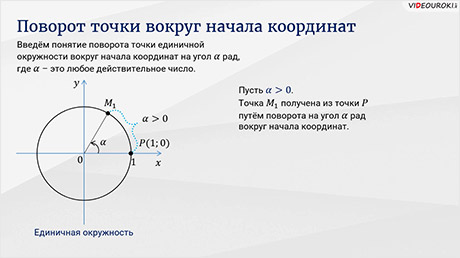

In [1]:
from IPython.display import Image
Image('IM_01.jpg', width=500, height=150 )

Если $x=(1,0)$, а $y=(\cos\alpha,\sin\alpha)$,
то скалярное произведение $x\cdot y=\cos\alpha.$
Скалярное произведение с единичным вектором оси x — это просто косинус угла, или же проекция на ось икс.

**Определение в общем виде**

**Def:** **Скалярным произведением** векторов $x = \sum_{j=1}^n a_j e_j$ и $y = \sum_{j=1}^n b_j e_j$ в простейшем виде называется число $\sum_{j=1}^n a_j b_j$

Скалярное произведение обозначается различными способами. Например,
$$x\cdot y, \quad (x, y), \quad\langle x \vert{} y\rangle$$

 **Нормой, или длиной вектора** $|x|$ называется число $\sqrt{(x, x)}$ - корень из скалярного произведения вектора на себя (если в рассматриваемом поле $F$ операция взятия корня определена). 
 
В соответствии со школьным пониманием, косинус в общем виде определяется как: $$\cos\alpha = \frac{(x, y)}{|x||y|}.$$ Геометрически скалярное произведение - это произведение длины вектора на длину проекции второго вектора на первый (или, что то же самое, в обратном порядке). 

Значит, косинус можно рассматривать как меру близости: чем больше скалярное произведение нормированных векторов, тем более сонаправлены эти векторы. Если скалярное произведение равно нулю, то векторы называются **ортогональными** (перпендикулярными).

## 1.3. Линейная регрессия.

Линейной моделью в машинном обучении называется функция вида:
$$y=w_1x_1+…+w_Dx_D+w_0 = (x, w) + w_0,$$
 $y$ — целевая переменная (таргет); ($x_1,…,x_D$) — вектор, соответствующий объекту выборки (вектор признаков/фичей/features); $w_1,…,w_D,w_0$ — параметры модели. Вектор $w=(w_1,…,w_D)$ часто называют вектором весов, так как на предсказание модели можно смотреть как на взвешенную сумму признаков объекта, а число $w_0$ — свободным коэффициентом, или сдвигом (англ. bias).

Если мы расширим векторы $x$, $w$ до $\widetilde x = (1, x_1,…,x_D)$ и $\widetilde w = (w_0, w_1,…,w_D)$, то мы можем записать уравнение регрессии в виде
$$y = (\widetilde x, \widetilde w).$$
Волны можно не писать.

Геометрически уравнение линейной регрессии задает прямую в двумерной плоскости, двумерную плоскость в трехмерном пространстве, ..., $n-1$ мерное пространство в $n$ мерном пространстве (гиперплоскость). 

# 2. Матрицы, матричные произведения. Трансформеры и Attention.

## 2.1. Основные определения и операции.

**Def:** **Матрицей** называется прямоугольная таблица чисел 
$$A = \begin{pmatrix}
a_{11} & a_{12} & ... & a_{1n}  \\
a_{21} & a_{22} & ... & a_{2n} \\
... \\
a_{m1} & a_{m2} & ... & a_{mn}
\end{pmatrix},$$
где $a_{ij}\in F$. Мнемоническое правило: первый индекс - номер строки, второй - номер столбца. 

**Def:** **Транспонирование матрицы.** Транспонированной матрицей к матрице $A =  \{a_{ij}\}, i=1,...,n, j=1,...,m$ размера $n\times m$ называется матрица $A^T = \{a_{ji}\}, i=1,...,n, j=1,...,m$ размера $m\times n$. для матрицы размера $n\times n$ транспонирование означает отражение относительно главной диагонали:
$$\begin{pmatrix}
a & b \\
c & d
\end{pmatrix}^T = \begin{pmatrix}
a & c \\
b & d
\end{pmatrix}.$$


**Def:** **Произведение матриц.** Для матриц $A = \{a_{ij}\}$ размерности $n\times m$ и $B = \{b_{ij}\}$ размерности $m\times k$ произведением называется матрица $C = A\cdot B$ размерностью $n \times k$:
$$c_{ij}=\sum_{p=1}^{m}a_{ip} b_{pj}.$$
"Промежуточная" размерность m "схлопывается", иначе говоря, перемножать можно только матрицы $A$ и $B$, у которых второе измерение $A$ совпадает с первым измерением $B$. Заметим, что элементы матрицы-произведения $C$ являются скалярными произведениями строк $A$ на столбцы $B$. 

**Def:** **Обратная матрица.** Для квадратной матрицы $A$ размера $n\times n$ обратной называется такая матрица $A^{-1}$, что $$A\cdot A^{-1} = A^{-1}A = I,$$
где $I$ (ее также обозначают $E$) - матрица, состоящая из единиц на главной диагонали. 


 
**Явное решение задачи регрессии и его геометрический смысл.** 

Пусть у нас есть набор ответов $y=(y_1,...,y_n)$ и признаков $X = \{x_{ij}\}, i=1,...,n,$ где $j=1,...,m$ - индекс номера признака. Чтобы обучать линейную регрессию (найти вектор $w$), надо минимизировать функцию $f(w)=|y−Xw|^2  =⟨y−Xw,y−Xw⟩$.

I. Решение с использованием математического анализа. Продифференцируем функцию $f$, приравняем к нулю производную. Это можно сделать непосредственно в координатах, либо правильно введя обозначения для производных векторов (прочитать про это можно тут https://contest.yandex.ru/tracks/ml/mathematical-foundations/matrix-calculus), получаем
$$∇wf=2X^T(Xw−y) = 0$$


II. Решение по геометрическим соображениям. Пусть $x_1,…,x_D$ – столбцы матрицы X, то есть столбцы признаков. Тогда
$Xw=w_1x_1+…+w_Dx_D,$ и задачу регрессии можно сформулировать следующим образом: найти линейную комбинацию столбцов $x_1,…,x_D$, которая наилучшим способом приближает столбец y по евклидовой норме – то есть найти проекцию вектора y на подпространство, образованное векторами $x_1,…,x_D$. Разложим $y=y^∥+y^⊥$, где $y^∥=Xw$ – та самая проекция, а $y^⊥$ – ортогональная составляющая, то есть 
$y^⊥=y−Xw$ ортогональна всем векторам $x_k$. Как мы обсуждали выше, ортогональность - это равенство нулю скалярного произведения, иначе говоря, получаем ту самую формулу
$X^T(y−Xw)=0$, где для компактности мы не рассматриваем умножение $y^⊥$ на каждый вектор слева, а группируем все в матрицу $X^T$.  

Если матрица $X^TX$ обратима, то решение уравнения имеет вид 
$$w=(X^TX)^{−1}X^Ty.$$
Однако, даже если эта матрица обратима, из-за слишком больших по модулю элементов этой матрицы, либо наооборот близких к нулю, либо перемножения таких элементов, численное решение этой системы может приводить к ошибочным результатам. Поэтому на практике эту задачу решают градиентным спуском.

**Def:** **Определитель (детерминант) матрицы.** 

Числовая характеристика (скаляр), которая ставится в соответствие только квадратной матрице.
Обозначения: $\det(A)$, $|A|$ или $Δ$.

• Определитель равен нулю тогда и только тогда, когда строки или столбцы матрицы линейно зависимы.

• Геометрический смысл: модуль определителя показывает, во сколько раз изменяется площадь (для матрицы 2×2) или объем (для матрицы 3×3) при линейном преобразовании пространства. Если $\det(A) = 0$, пространство «схлопывается» в размерность меньше (например, объем трехмерного параллелепипеда равен нулю).

• Алгебраический смысл: матрица имеет обратную тогда и только тогда, когда ее определитель не равен нулю $\det(A) \neq 0$. Определители используются в правиле Крамера для решения систем линейных уравнений.

Для матрицы первого порядка значение '''детерминанта''' равно единственному элементу этой матрицы:

$$\Delta=\begin{vmatrix} a_{11}\end{vmatrix} = a_{11}.$$

Для матрицы $2 \times 2$ определитель вычисляется как:

$$\Delta=\begin{vmatrix} a & c \\ b & d \end{vmatrix}=ad-bc.$$

В общем случае, для матриц более высоких порядков (выше 2-го порядка) определитель можно вычислить, применив следующую рекурсивную формулу:

$$\Delta=\sum_{j=1}^n (-1)^{1+j} a_{1j}\bar M_j^1,$$ где $\bar M_j^1$ — дополнительный минор к элементу $a_{1j}$ - определитель матрицы $A$ с вычеркнутой первой строкой и $j$-м столбцом. Эта формула называется '''разложением по (первой) строке'''.


## 2.2. Трансформеры и Attention.

Основным блоком современных больших языковых (LLM), или же трансформерных моделей, таких как GPT и DeepSeek, является Attention-блок.
$$Attention(X) = softmax\left(\frac{(X\cdot W_Q)\cdot (X\cdot W_K)^T}{\sqrt{d_K}}\right)\cdot (X\cdot W_V),$$
где $X$ - входящие данные в матричном виде, $W_{Q, K, V}$ - обучаемые веса - тоже матрицы, причем $d_K$ - размерность, которая "сворачивается" при умножении, $\cdot$ - матричное умножение. Деление на $\sqrt{d_K}$ происходит поэлементно. Ну а $softmax(Z)_{ij} = exp(z_{ij})/ \sum_j(exp(z_{ij}))$ - построчная нормировка.

Ключевой идеей является проверка схожести каждого элемента входящих данных c каждым другим через умножение $(X\cdot W_Q)\cdot (X\cdot W_K)^T$.